EXPLORATORY DATA ANALYSIS ON CAR DATASET

Dataset:Car details from CarDekho(public kaggle dataset)

Dataset page:https://www.kaggle.com/datasets/akshaydattatraykhare/car-details-dataset


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

DATA_FILE = "CAR DETAILS FROM CAR DEKHO.csv"
df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully.")
print("Shape:", df.shape)


Dataset loaded successfully.
Shape: (4340, 8)


1.Data **unerstandng**

In [3]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

print("\nSample rows:")
display(df.head())

print("\nData types:")
display(df.dtypes)

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("\nNumerical variables:", numeric_cols)
print("Categorical variables:", categorical_cols)


Rows: 4340
Columns: 8

Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Sample rows:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner



Data types:


,0
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object



Numerical variables: ['year', 'selling_price', 'km_driven']
Categorical variables: ['name', 'fuel', 'seller_type', 'transmission', 'owner']


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3577 entries, 0 to 4339
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           3577 non-null   object
 1   year           3577 non-null   int64 
 2   selling_price  3577 non-null   int64 
 3   km_driven      3577 non-null   int64 
 4   fuel           3577 non-null   object
 5   seller_type    3577 non-null   object
 6   transmission   3577 non-null   object
 7   owner          3577 non-null   object
 8   car_age        3577 non-null   int64 
 9   brand          3577 non-null   object
dtypes: int64(4), object(6)
memory usage: 307.4+ KB


2.Data quality checks

In [4]:
print("Missing values:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())

for col in categorical_cols:
    print(f"\nUnique values in {col}:")
    print(df[col].value_counts(dropna=False).head(15))


Missing values:


,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


Duplicate rows: 763

Unique values in name:
name
Maruti Swift Dzire VDI      69
Maruti Alto 800 LXI         59
Maruti Alto LXi             47
Hyundai EON Era Plus        35
Maruti Alto LX              35
Maruti Swift VDI BSIV       29
Maruti Wagon R VXI BS IV    29
Maruti Swift VDI            27
Maruti Wagon R LXI Minor    24
Hyundai EON Magna Plus      24
Maruti Wagon R LXI          23
Maruti 800 AC               23
Maruti Ritz VDi             22
Hyundai i10 Magna           22
Mahindra XUV500 W8 2WD      22
Name: count, dtype: int64

Unique values in fuel:
fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

Unique values in seller_type:
seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

Unique values in transmission:
transmission
Manual       3892
Automatic     448
Name: count, dtype: int64

Unique values in owner:
owner
First Owner             2832
Second Ow

3.Cleaning

In [5]:
before_rows = len(df)

# Remove exact duplicate records because they do not add new observations.
df = df.drop_duplicates().copy()

# Standardize text columns by trimming whitespace.
for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip()

# Ensure numerical columns have numeric types.
for col in ["year", "selling_price", "km_driven"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove records with missing essential numeric values.
df = df.dropna(subset=["year", "selling_price", "km_driven"]).copy()

# Create useful derived variables.
df["car_age"] = pd.Timestamp.now().year - df["year"]

after_rows = len(df)

print("Rows before cleaning:", before_rows)
print("Rows after cleaning:", after_rows)
print("Rows removed:", before_rows - after_rows)
display(df.head())

Rows before cleaning: 4340
Rows after cleaning: 3577
Rows removed: 763


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,19
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,19
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,14
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,9
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,12


4.Statistics

In [6]:
print("Numerical summary:")
display(df[numeric_cols + ["car_age"]].describe().T)

print("Categorical summary:")
display(df[categorical_cols].describe().T)

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
year,3577.0,2012.962538,4.251759,1992.0,2010.0,2013.0,2016.0,2020.0
selling_price,3577.0,473912.542074,509301.809816,20000.0,200000.0,350000.0,600000.0,8900000.0
km_driven,3577.0,69250.545709,47579.940016,1.0,36000.0,60000.0,90000.0,806599.0
car_age,3577.0,13.037462,4.251759,6.0,10.0,13.0,16.0,34.0


Categorical summary:


,count,unique,top,freq
name,3577,1491,Maruti Swift Dzire VDI,54
fuel,3577,5,Diesel,1800
seller_type,3577,3,Individual,2832
transmission,3577,2,Manual,3265
owner,3577,5,First Owner,2218


5.Univariate analysis

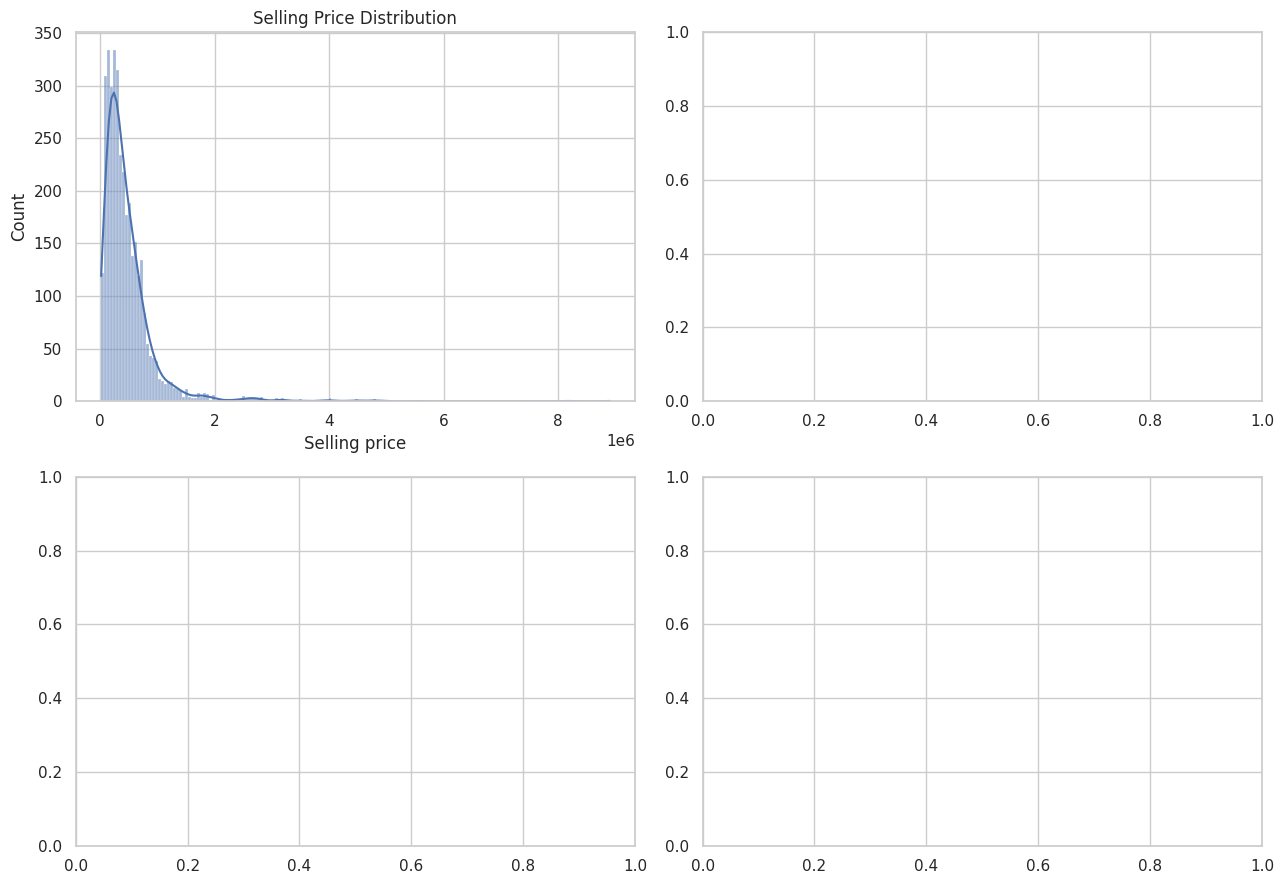

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(df["selling_price"], kde=True, ax=axes[0,0])
axes[0,0].set_title("Selling Price Distribution")
axes[0,0].set_xlabel("Selling price")
plt.tight_layout()
plt.show()

6.Bivariate analysis

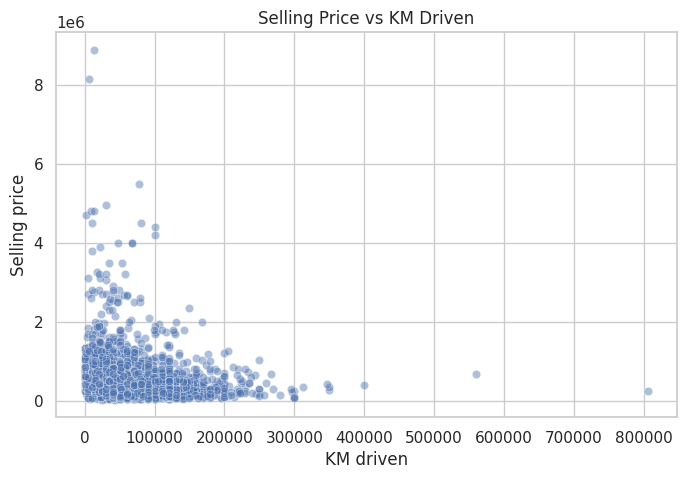

In [9]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="km_driven", y="selling_price", alpha=0.45)
plt.title("Selling Price vs KM Driven")
plt.xlabel("KM driven")
plt.ylabel("Selling price")
plt.show()


7.Multivariate analysis

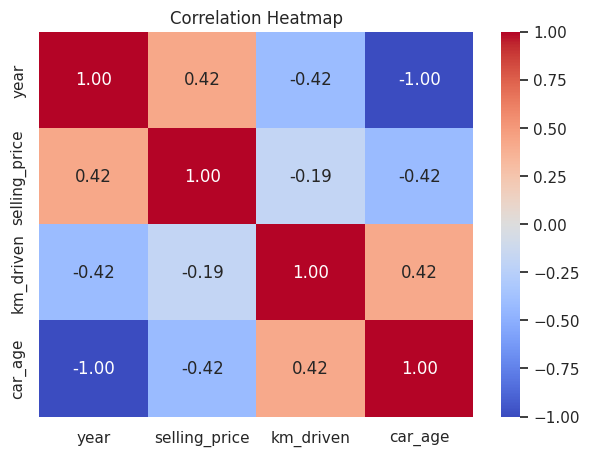

Correlation with selling price:


,selling_price
selling_price,1.000000
year,0.424260
km_driven,-0.187359
car_age,-0.424260


In [10]:
numeric_for_corr = df[["year", "selling_price", "km_driven", "car_age"]]
corr_matrix = numeric_for_corr.corr()

plt.figure(figsize=(7,5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

print("Correlation with selling price:")
display(corr_matrix["selling_price"].sort_values(ascending=False))

8.Brand analysis

Top 10 brands by number of listings:


,count
brand,
Maruti,1072
Hyundai,637
Mahindra,328
Tata,308
Ford,220
Honda,216
Toyota,170
Chevrolet,151
Renault,110


Average selling price for brands with at least 30 listings:


,count,mean
brand,,
Audi,31,2.185452e+06
Toyota,170,8.389176e+05
Mahindra,328,5.847804e+05
Ford,220,5.636272e+05
Honda,216,5.399444e+05
Skoda,49,4.755510e+05
Volkswagen,93,4.616666e+05
Nissan,52,4.570384e+05
Hyundai,637,4.133406e+05


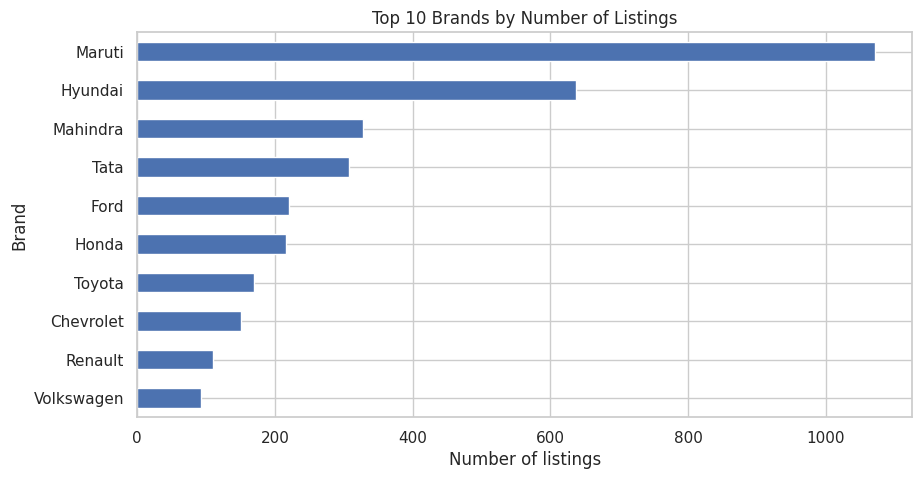

In [11]:
df["brand"] = df["name"].str.split().str[0]

brand_counts = df["brand"].value_counts()
print("Top 10 brands by number of listings:")
display(brand_counts.head(10))

brand_price = df.groupby("brand")["selling_price"].agg(["count","mean"]).sort_values("count", ascending=False)
print("Average selling price for brands with at least 30 listings:")
display(brand_price[brand_price["count"] >= 30].sort_values("mean", ascending=False).head(10))

plt.figure(figsize=(10,5))
brand_counts.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Brands by Number of Listings")
plt.xlabel("Number of listings")
plt.ylabel("Brand")
plt.show()

9.Outlier detection

selling_price: Q1=200000.00, Q3=600000.00, IQR=400000.00, lower=-400000.00, upper=1200000.00, outliers=170
km_driven: Q1=36000.00, Q3=90000.00, IQR=54000.00, lower=-45000.00, upper=171000.00, outliers=106


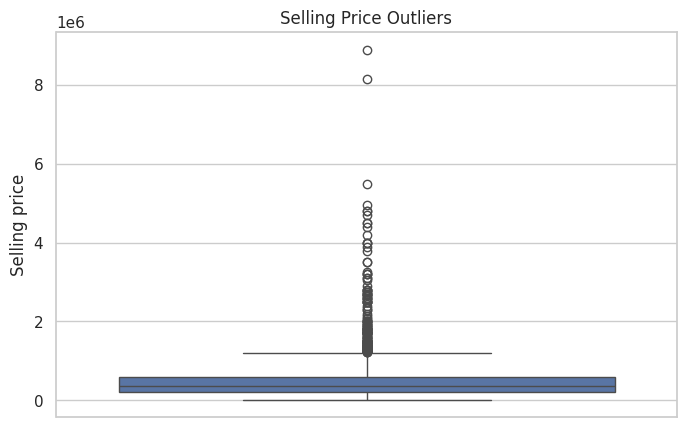

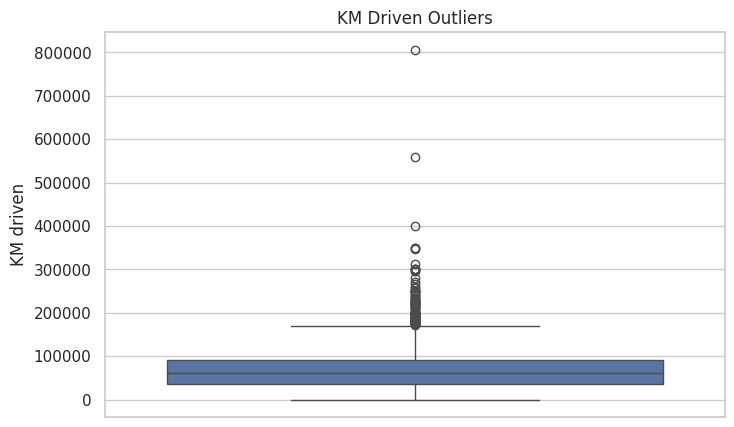

In [12]:
def outlier_summary(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return q1, q3, iqr, lower, upper, int(mask.sum())

for col in ["selling_price", "km_driven"]:
    q1, q3, iqr, lower, upper, count = outlier_summary(df[col])
    print(f"{col}: Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, lower={lower:.2f}, upper={upper:.2f}, outliers={count}")

plt.figure(figsize=(8,5))
sns.boxplot(y=df["selling_price"])
plt.title("Selling Price Outliers")
plt.ylabel("Selling price")
plt.show()

plt.figure(figsize=(8,5))
sns.boxplot(y=df["km_driven"])
plt.title("KM Driven Outliers")
plt.ylabel("KM driven")
plt.show()


In [16]:
print("1. The dataset contains", len(df), "cleaned observations.")
print("2. The most common fuel type is", df["fuel"].mode()[0], "with", df["fuel"].value_counts().iloc[0], "listings.")
print("3. The most common transmission is", df["transmission"].mode()[0], "with", df["transmission"].value_counts().iloc[0], "listings.")
print("4. Correlation between selling price and year:", round(df["selling_price"].corr(df["year"]), 3))
print("5. Correlation between selling price and KM driven:", round(df["selling_price"].corr(df["km_driven"]), 3))
print("6. The most represented brand is", df["brand"].mode()[0], "with", df["brand"].value_counts().iloc[0], "listings.")


1. The dataset contains 3577 cleaned observations.
2. The most common fuel type is Diesel with 1800 listings.
3. The most common transmission is Manual with 3265 listings.
4. Correlation between selling price and year: 0.424
5. Correlation between selling price and KM driven: -0.187
6. The most represented brand is Maruti with 1072 listings.


10.limitations

.The dataset is a used car listing dataset and does not necessarily represent the complete automobile task

.listing prices may differ from final transaction prices

.correlation does not prove causation

.some brands or models have very few observations

11.Conclusion


The EDA shows how basic data quality checks,descriptive stastics and visual analysis can reval useful patterns in used car5 data.vehicle year,kilometers driven,fuel type,transmission,ownership and brand all provide useful context for understanding resale listings